# 使用说明
从上到下逐格运行。每格下方已有本次实际执行输出，不需要先运行也能读。
改参数后请重新运行后续格。图中数字幅度没有校准成声压，不代表耳机声压大小。
仅使用 NumPy、SciPy、Matplotlib；不录音、不自动播放、不下载模型。
图形显示由本机已安装的中文字体决定；本次生成使用微软雅黑。


# 练习本一：亲手制造一个声音数组

目标：分清采样率、频率、长度、幅度。先猜一秒音频有多少个数，再运行。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
fs = 16000                 # 每秒记录16000个数，不是音调频率
duration = 1.0             # 声音持续一秒
frequency = 440            # 每秒振动440次
t = np.arange(int(fs * duration)) / fs  # 数组索引除采样率，单位变成秒
x = 0.5 * np.sin(2 * np.pi * frequency * t)  # 数字幅度最大约0.5
print('数组形状：', x.shape, '时长：', len(x)/fs, '秒')
print('前5个样本：', np.round(x[:5], 4))
assert len(x) == 16000


数组形状： (16000,) 时长： 1.0 秒
前5个样本： [0.     0.086  0.1694 0.2477 0.3187]


这里 x.shape=(16000,) 是一维数组，不是16000个声道。只看前10毫秒，就能看清周期；整秒挤在一张图里只会像一条色带。


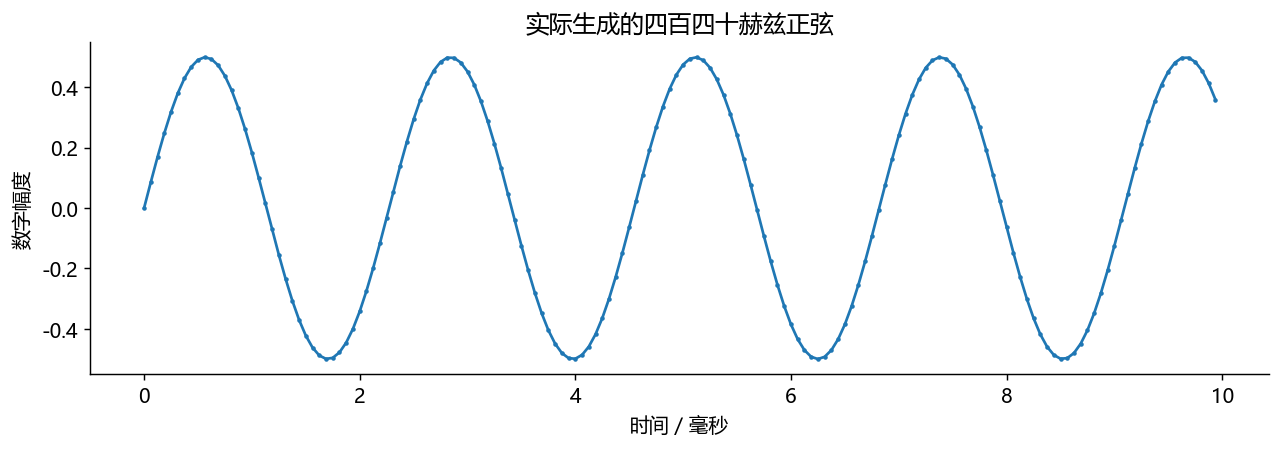

In [2]:
shown = int(0.01 * fs)      # 十毫秒对应160个样本
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(t[:shown] * 1000, x[:shown], marker='.', markersize=3)
ax.set(xlabel='时间／毫秒', ylabel='数字幅度', title='实际生成的四百四十赫兹正弦')
fig.tight_layout()


图上相邻同方向过零之间是一周期。440 Hz 的周期约2.27 ms，10 ms 内约4.4周期。现在把频率加倍，观察周期数而不是曲线高度。


两个信号的RMS： 0.3535533905932735 0.35355339059327373


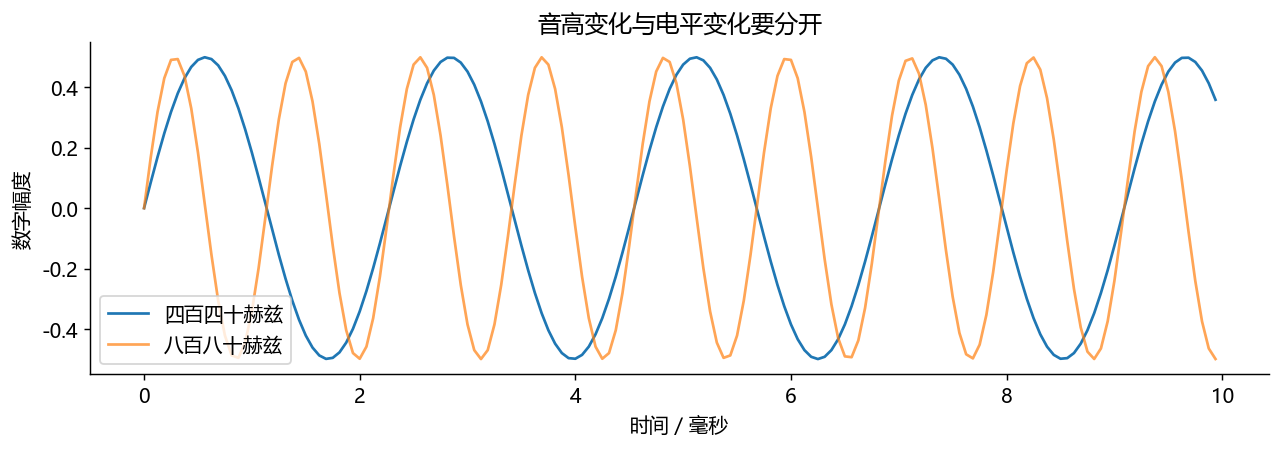

In [3]:
x2 = 0.5 * np.sin(2 * np.pi * 880 * t)  # 只改频率，不改振幅
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(t[:shown]*1000, x[:shown], label='四百四十赫兹')
ax.plot(t[:shown]*1000, x2[:shown], alpha=.7, label='八百八十赫兹')
ax.set(xlabel='时间／毫秒', ylabel='数字幅度', title='音高变化与电平变化要分开')
ax.legend(); fig.tight_layout()
print('两个信号的RMS：', np.sqrt(np.mean(x*x)), np.sqrt(np.mean(x2*x2)))


练习：幅度改0.25，频率不变。预期：周期不变，峰值减半，RMS减半。不要为了听得清楚主动调高设备音量；本课不自动播放声音。
